In [8]:
!pip install ultralytics roboflow

In [9]:
import ultralytics
import roboflow
print ("YOLO version:",
       ultralytics.__version__)
print("roboflow is ready!")

YOLO version: 8.4.218
roboflow is ready!


In [10]:
from google.colab import userdata
from roboflow import Roboflow

api_key = userdata.get("ROBOFLOW_API_KEY")

rf = Roboflow(api_key=api_key)

print("Roboflow connected successfully!")

Roboflow connected successfully!


In [11]:
project1 = rf.workspace("krum-dala").project("pipe-defects-ybzjr")

print("Dataset name:", project1.name)
print("Available versions:", project1.versions())

loading Roboflow workspace...
loading Roboflow project...
Dataset name: Pipe defects
Available versions: [<roboflow.core.version.Version object at 0x789d7294ed50>, <roboflow.core.version.Version object at 0x789d7294f2f0>]


In [12]:
for version in project1.versions():
    print("Version:", version.version)
    print("Images:", version.images)
    print("-------------------")

Version: 5
Images: 146
-------------------
Version: 4
Images: 146
-------------------


In [13]:
v5 = project1.version(5)

print("Version information:")
print(dir(v5))

Version information:
['_Version__api_key', '_Version__check_if_generating', '_Version__download_zip', '_Version__get_download_location', '_Version__get_download_url', '_Version__get_format_identifier', '_Version__reformat_yaml', '_Version__wait_if_generating', '__class__', '__delattr__', '__dict__', '__dir__', '__doc__', '__eq__', '__firstlineno__', '__format__', '__ge__', '__getattribute__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__lt__', '__module__', '__ne__', '__new__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__sizeof__', '__static_attributes__', '__str__', '__subclasshook__', '__weakref__', '_model', '_upload_zip', '_validate_against_project_type', 'augmentation', 'colors', 'create_training', 'created', 'delete', 'delete_training', 'deploy', 'describe_train_recipe', 'download', 'export', 'exports', 'id', 'images', 'model', 'model_format', 'models', 'name', 'preprocessing', 'project', 'public', 'restore', 'restore_traini

In [14]:
dataset1 = project1.version(5).download("yolov8")

print("Dataset 1 downloaded successfully!")
print("Location:", dataset1.location)


Extracting Dataset Version Zip to Pipe-defects-5 in yolov8:: 100%|██████████| 196/196 [00:00<00:00, 1330.67it/s]


Dataset 1 downloaded successfully!
Location: /content/Pipe-defects-5


In [15]:
import yaml

with open(dataset1.location + "/data.yaml", "r") as file:
    data = yaml.safe_load(file)

print("Defect classes:", data["names"])
print("Number of classes:", data["nc"])

Defect classes: ['crack', 'hole', 'rupture']
Number of classes: 3


In [16]:
project2 = rf.workspace("pipe").project("pipe-inspection")

dataset2 = project2.version(1).download("yolov8")

print("Dataset 2 downloaded!")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Pipe-Inspection-1 in yolov8:: 100%|██████████| 708/708 [00:00<00:00, 3082.90it/s]

Dataset 2 downloaded!


In [17]:
project3 = rf.workspace("1463597570s-workspace").project("pipe-corrosion-project")

dataset3 = project3.version(1).download("yolov8")

print("Dataset 3 downloaded!")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Pipe-Corrosion-Project-1 in yolov8:: 100%|██████████| 2151/2151 [00:00<00:00, 2933.80it/s]

Dataset 3 downloaded!


In [18]:
import yaml
import os

datasets = {
    "Dataset 1 - Pipe Defects": dataset1,
    "Dataset 2 - Pipe Inspection": dataset2,
    "Dataset 3 - Pipe Corrosion": dataset3
}

for name, dataset in datasets.items():
    path = os.path.join(dataset.location, "data.yaml")

    with open(path, "r") as file:
        data = yaml.safe_load(file)

    print("\n", name)
    print("Defect classes:", data["names"])
    print("Total classes:", data["nc"])


 Dataset 1 - Pipe Defects
Defect classes: ['crack', 'hole', 'rupture']
Total classes: 3

 Dataset 2 - Pipe Inspection
Defect classes: ['crack', 'rust', 'void']
Total classes: 3

 Dataset 3 - Pipe Corrosion
Defect classes: ['0', '1']
Total classes: 2


In [19]:
import yaml
import os

path = os.path.join(dataset3.location, "data.yaml")

with open(path, "r") as file:
    data3 = yaml.safe_load(file)

print(data3)

{'names': ['0', '1'], 'nc': 2, 'roboflow': {'license': 'CC BY 4.0', 'project': 'pipe-corrosion-project', 'url': 'https://universe.roboflow.com/1463597570s-workspace/pipe-corrosion-project/dataset/1', 'version': 1, 'workspace': '1463597570s-workspace'}, 'test': '../test/images', 'train': '../train/images', 'val': '../valid/images'}


In [20]:
import yaml

with open(dataset2.location + "/data.yaml", "r") as file:
    data = yaml.safe_load(file)

print("Defect classes:", data["names"])
print("Number of classes:", data["nc"])

Defect classes: ['crack', 'rust', 'void']
Number of classes: 3


In [21]:
import yaml

with open(dataset3.location + "/data.yaml", "r") as file:
    data = yaml.safe_load(file)

print("Defect classes:", data["names"])
print("Number of classes:", data["nc"])

Defect classes: ['0', '1']
Number of classes: 2


In [22]:
print(data3)

{'names': ['0', '1'], 'nc': 2, 'roboflow': {'license': 'CC BY 4.0', 'project': 'pipe-corrosion-project', 'url': 'https://universe.roboflow.com/1463597570s-workspace/pipe-corrosion-project/dataset/1', 'version': 1, 'workspace': '1463597570s-workspace'}, 'test': '../test/images', 'train': '../train/images', 'val': '../valid/images'}


In [23]:
data3["names"] = {
    0: "Crack",
    1: "Corrosion"
}

print("Updated classes:", data3["names"])

Updated classes: {0: 'Crack', 1: 'Corrosion'}


In [24]:
with open(path, "w") as file:
    yaml.safe_dump(data3, file, sort_keys=False)

In [25]:
import yaml

with open(dataset3.location + "/data.yaml", "r") as file:
    data = yaml.safe_load(file)

print("Defect classes:", data["names"])
print("Number of classes:", data["nc"])

Defect classes: {0: 'Crack', 1: 'Corrosion'}
Number of classes: 2


In [26]:
common_classes = [
    "crack",
    "hole",
    "rupture",
    "rust",
    "corrosion",
    "void",
    "joint"
]

print("Total defect classes:", len(common_classes))

for i, name in enumerate(common_classes):
    print(i, ":", name)

Total defect classes: 7
0 : crack
1 : hole
2 : rupture
3 : rust
4 : corrosion
5 : void
6 : joint


In [27]:
import yaml
import os

for i, ds in enumerate([dataset1, dataset2, dataset3], 1):
    path = os.path.join(ds.location, "data.yaml")

    with open(path, "r") as f:
        info = yaml.safe_load(f)

    print(f"\nDATASET {i}")
    print("Names:", info["names"])
    print("Number of classes:", info["nc"])


DATASET 1
Names: ['crack', 'hole', 'rupture']
Number of classes: 3

DATASET 2
Names: ['crack', 'rust', 'void']
Number of classes: 3

DATASET 3
Names: {0: 'Crack', 1: 'Corrosion'}
Number of classes: 2


In [28]:
import os

datasets = {
    "Dataset 1": dataset1,
    "Dataset 2": dataset2,
    "Dataset 3": dataset3
}

for name, ds in datasets.items():
    print("\n", name)

    for folder in ["train", "valid", "test"]:
        image_folder = os.path.join(ds.location, folder, "images")

        if os.path.exists(image_folder):
            count = len(os.listdir(image_folder))
            print(folder, "images:", count)


 Dataset 1
train images: 72
valid images: 14
test images: 6

 Dataset 2
train images: 302
valid images: 31
test images: 15

 Dataset 3
train images: 858
valid images: 108
test images: 107


In [29]:
for i, ds in enumerate([dataset1, dataset2, dataset3], 1):
    import yaml, os

    with open(os.path.join(ds.location, "data.yaml")) as f:
        info = yaml.safe_load(f)

    print(f"Dataset {i}:")
    print("Classes:", info["names"])
    print()

Dataset 1:
Classes: ['crack', 'hole', 'rupture']

Dataset 2:
Classes: ['crack', 'rust', 'void']

Dataset 3:
Classes: {0: 'Crack', 1: 'Corrosion'}



In [30]:
import os

base_dir = "/content/Combined_Pipe_Dataset"

os.makedirs(base_dir, exist_ok=True)

print("Combined dataset folder created!")
print(base_dir)

Combined dataset folder created!
/content/Combined_Pipe_Dataset


In [31]:
import yaml
import os

for i, ds in enumerate([dataset1, dataset2, dataset3], 1):
    with open(os.path.join(ds.location, "data.yaml")) as f:
        info = yaml.safe_load(f)

    print(f"\nDataset {i}:")
    print("Original class names:", info["names"])


Dataset 1:
Original class names: ['crack', 'hole', 'rupture']

Dataset 2:
Original class names: ['crack', 'rust', 'void']

Dataset 3:
Original class names: {0: 'Crack', 1: 'Corrosion'}


In [32]:
common_classes = {
    0: "crack",
    1: "hole",
    2: "rupture",
    3: "rust",
    4: "void",
    5: "corrosion"
}

print("FINAL DEFECT CLASS MAPPING")

for class_id, name in common_classes.items():
    print(f"{class_id}: {name}")

FINAL DEFECT CLASS MAPPING
0: crack
1: hole
2: rupture
3: rust
4: void
5: corrosion


In [33]:
import os
from collections import Counter

datasets = [dataset1, dataset2, dataset3]

for i, ds in enumerate(datasets, 1):
    counts = Counter()

    for split in ["train", "valid", "test"]:
        label_dir = os.path.join(ds.location, split, "labels")

        if not os.path.exists(label_dir):
            continue

        for file in os.listdir(label_dir):
            if file.endswith(".txt"):
                with open(os.path.join(label_dir, file)) as f:
                    for line in f:
                        if line.strip():
                            counts[line.split()[0]] += 1

    print(f"\nDataset {i} class IDs:", dict(counts))


Dataset 1 class IDs: {'1': 335, '2': 115, '0': 122}

Dataset 2 class IDs: {'0': 175, '1': 115, '2': 115}

Dataset 3 class IDs: {'1': 903, '0': 589}


In [34]:
label_maps = {
    1: {0: 0, 1: 1, 2: 2},
    2: {0: 0, 1: 3, 2: 4},
    3: {0: 0, 1: 5}
}

print("Label mapping ready!")

Label mapping ready!


In [35]:
import yaml
import os

for i, ds in enumerate([dataset1, dataset2, dataset3], 1):
    path = os.path.join(ds.location, "data.yaml")

    with open(path, "r") as f:
        info = yaml.safe_load(f)

    print(f"\nDataset {i}")
    print("Class mapping:", info["names"])


Dataset 1
Class mapping: ['crack', 'hole', 'rupture']

Dataset 2
Class mapping: ['crack', 'rust', 'void']

Dataset 3
Class mapping: {0: 'Crack', 1: 'Corrosion'}


In [36]:
import yaml
import os

for i, ds in enumerate([dataset1, dataset2, dataset3], 1):
    with open(os.path.join(ds.location, "data.yaml")) as f:
        info = yaml.safe_load(f)

    print(f"\nDataset {i}")
    print("Classes:", info["names"])


Dataset 1
Classes: ['crack', 'hole', 'rupture']

Dataset 2
Classes: ['crack', 'rust', 'void']

Dataset 3
Classes: {0: 'Crack', 1: 'Corrosion'}


In [37]:
import os

base_dir = "/content/Combined_Pipe_Dataset"

for split in ["train", "valid", "test"]:
    os.makedirs(f"{base_dir}/{split}/images", exist_ok=True)
    os.makedirs(f"{base_dir}/{split}/labels", exist_ok=True)

print("Combined dataset folders ready!")

Combined dataset folders ready!


In [38]:
label_maps = {
    1: {0: 0, 1: 1, 2: 2},
    2: {0: 0, 1: 3, 2: 4},
    3: {0: 0, 1: 5}
}

In [39]:
import yaml

final_config = {
    "path": base_dir,
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": 6,
    "names": [
        "crack",
        "hole",
        "rupture",
        "rust",
        "void",
        "corrosion"
    ]
}

with open(f"{base_dir}/data.yaml", "w") as f:
    yaml.safe_dump(final_config, f, sort_keys=False)

print("YOLO configuration created!")

YOLO configuration created!


In [40]:
import os

datasets = [dataset1, dataset2, dataset3]

for i, ds in enumerate(datasets, 1):
    print(f"\nDATASET {i}")
    print("Location:", ds.location)

    for split in ["train", "valid", "test"]:
        folder = os.path.join(ds.location, split, "images")

        if os.path.exists(folder):
            print(split, ":", len(os.listdir(folder)), "images")
        else:
            print(split, ": folder not found")


DATASET 1
Location: /content/Pipe-defects-5
train : 72 images
valid : 14 images
test : 6 images

DATASET 2
Location: /content/Pipe-Inspection-1
train : 302 images
valid : 31 images
test : 15 images

DATASET 3
Location: /content/Pipe-Corrosion-Project-1
train : 858 images
valid : 108 images
test : 107 images


In [41]:
import os
import yaml
import shutil
import hashlib

base_dir = "/content/Combined_Pipe_Dataset"

class_names = [
    "crack",
    "hole",
    "rupture",
    "rust",
    "void",
    "corrosion"
]

# Original class ID to new class ID
label_maps = {
    1: {0: 0, 1: 1, 2: 2},
    2: {0: 0, 1: 3, 2: 4},
    3: {0: 0, 1: 5}
}

datasets = [dataset1, dataset2, dataset3]
splits = ["train", "valid", "test"]

# Create folders
for split in splits:
    os.makedirs(f"{base_dir}/{split}/images", exist_ok=True)
    os.makedirs(f"{base_dir}/{split}/labels", exist_ok=True)

seen_images = set()
copied = 0
duplicates = 0

for i, ds in enumerate(datasets, 1):

    for split in splits:

        img_dir = os.path.join(ds.location, split, "images")
        lbl_dir = os.path.join(ds.location, split, "labels")

        if not os.path.isdir(img_dir):
            continue

        for img in os.listdir(img_dir):

            img_path = os.path.join(img_dir, img)

            with open(img_path, "rb") as f:
                image_hash = hashlib.md5(f.read()).hexdigest()

            if image_hash in seen_images:
                duplicates += 1
                continue

            label_file = os.path.splitext(img)[0] + ".txt"
            label_path = os.path.join(lbl_dir, label_file)

            if not os.path.exists(label_path):
                raise FileNotFoundError(
                    f"Missing label: {label_path}"
                )

            new_lines = []

            with open(label_path, "r") as f:
                for line in f:
                    parts = line.split()

                    if not parts:
                        continue

                    old_id = int(parts[0])
                    new_id = label_maps[i][old_id]

                    new_lines.append(
                        " ".join([str(new_id)] + parts[1:])
                    )

            new_name = f"ds{i}_{img}"
            new_label = os.path.splitext(new_name)[0] + ".txt"

            shutil.copy2(
                img_path,
                f"{base_dir}/{split}/images/{new_name}"
            )

            with open(
                f"{base_dir}/{split}/labels/{new_label}", "w"
            ) as f:
                f.write("\n".join(new_lines))

            seen_images.add(image_hash)
            copied += 1

# Create YOLO configuration
config = {
    "path": base_dir,
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": len(class_names),
    "names": class_names
}

with open(f"{base_dir}/data.yaml", "w") as f:
    yaml.safe_dump(config, f, sort_keys=False)

print("MERGING COMPLETED!")
print("Images copied:", copied)
print("Duplicate images skipped:", duplicates)

for split in splits:
    count = len(os.listdir(f"{base_dir}/{split}/images"))
    print(split, "images:", count)

MERGING COMPLETED!
Images copied: 1513
Duplicate images skipped: 0
train images: 1232
valid images: 153
test images: 128


In [42]:
import os
import yaml

base_dir = "/content/Combined_Pipe_Dataset"

with open(f"{base_dir}/data.yaml", "r") as f:
    data = yaml.safe_load(f)

print("CLASSES:", data["names"])
print("NUMBER OF CLASSES:", data["nc"])

for split in ["train", "valid", "test"]:
    images = len(os.listdir(f"{base_dir}/{split}/images"))
    labels = len(os.listdir(f"{base_dir}/{split}/labels"))

    print(f"{split}: {images} images | {labels} labels")

CLASSES: ['crack', 'hole', 'rupture', 'rust', 'void', 'corrosion']
NUMBER OF CLASSES: 6
train: 1232 images | 1232 labels
valid: 153 images | 153 labels
test: 128 images | 128 labels


In [46]:
import torch
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

GPU: Tesla T4


In [47]:
from ultralytics import YOLO
import torch

if not torch.cuda.is_available():
    raise RuntimeError("GPU not available. Enable T4 GPU in Runtime settings.")

model = YOLO("yolo11n.pt")

results = model.train(
    data="/content/Combined_Pipe_Dataset/data.yaml",
    epochs=20,
    imgsz=416,
    batch=8,
    device=0,
    workers=2,
    project="/content/pipe_runs",
    name="pipe_defect_model",
    plots=True,
    patience=7
)

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Combined_Pipe_Dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=416, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=pipe_defect_model, nbs=64, nms=None, opset=None,

In [48]:
from ultralytics import YOLO

model = YOLO("/content/pipe_runs/pipe_defect_model/weights/best.pt")

metrics = model.val(
    data="/content/Combined_Pipe_Dataset/data.yaml",
    split="test",
    imgsz=416,
    batch=8,
    device=0,
    plots=True
)

print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)
print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,598,266 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1226.9±298.0 MB/s, size: 39.5 KB)
val: Scanning /content/Combined_Pipe_Dataset/test/labels... 128 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 128/128 2.0Kit/s 0.1s
val: New cache created: /content/Combined_Pipe_Dataset/test/labels.cache
WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 7, len(boxes) = 189. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 16/16 9.7it/s 1.6s
                   all        128        189      0.603      0.466       0.53      0.301
                 crack         61         76        

In [49]:
from ultralytics import YOLO

model = YOLO("/content/pipe_runs/pipe_defect_model/weights/best.pt")

model.predict(
    source="/content/Combined_Pipe_Dataset/test/images",
    imgsz=416,
    conf=0.25,
    device=0,
    save=True,
    project="/content/pipe_runs",
    name="predictions"
)

print("Prediction images saved successfully!")


image 1/128 /content/Combined_Pipe_Dataset/test/images/ds1_Detail-on-a-deformed-gas-pipeline-with-a-transverse-crack-in-the-length-of-about-20cm_jpg.rf.096a5cfc12c62a52410378c88a094491.jpg: 320x416 (no detections), 8.9ms
image 2/128 /content/Combined_Pipe_Dataset/test/images/ds1_TT3-Fig-3_jpg.rf.32985962aadb1e65cfea996b581877ad.jpg: 288x416 (no detections), 24.6ms
image 3/128 /content/Combined_Pipe_Dataset/test/images/ds1_corrosion-under-insulation-cui-testing-and-inspections-icon_jpg.rf.574f710b6cdb5b7a657348a2272b0401.jpg: 320x416 1 crack, 11.0ms
image 4/128 /content/Combined_Pipe_Dataset/test/images/ds1_istockphoto-457208459-612x612_jpg.rf.a4961bf1833804b0673ff9a89143ce26.jpg: 288x416 (no detections), 11.7ms
image 5/128 /content/Combined_Pipe_Dataset/test/images/ds1_istockphoto-908385376-612x612_jpg.rf.ca7aa05514fee656a18a65d32df13a1f.jpg: 288x416 1 crack, 16.7ms
image 6/128 /content/Combined_Pipe_Dataset/test/images/ds1_pipes_jpg.rf.0e709cf8e2683f31220806221d28cf72.jpg: 192x416 1 

In [50]:
from google.colab import files

files.download(
    "/content/pipe_runs/pipe_defect_model/weights/best.pt"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [51]:
import shutil
from google.colab import files

shutil.make_archive(
    "/content/Pipe_Defect_Project_Results",
    "zip",
    "/content/pipe_runs"
)

files.download("/content/Pipe_Defect_Project_Results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [52]:
import os
import pandas as pd
from ultralytics import YOLO

results_dir = "/content/pipe_runs/pipe_defect_model"

# Training results
df = pd.read_csv(os.path.join(results_dir, "results.csv"))
print("TRAINING RESULTS:")
display(df.tail())

# Model information
model = YOLO(os.path.join(results_dir, "weights/best.pt"))
print("\nMODEL CLASSES:")
print(model.names)

print("\nMODEL FILE SIZE:")
print(round(os.path.getsize(os.path.join(results_dir, "weights/best.pt")) / (1024**2), 2), "MB")

TRAINING RESULTS:


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
15,16,287.052,1.53276,1.37477,1.57387,0.71683,0.44309,0.49929,0.26492,1.64897,1.55464,1.62463,0.000258,0.000258,0.000258
16,17,304.115,1.49147,1.32093,1.53980,0.68763,0.46256,0.49784,0.28536,1.61032,1.47616,1.57781,0.000208,0.000208,0.000208
17,18,321.650,1.46102,1.24281,1.50566,0.85724,0.45762,0.50210,0.28470,1.63980,1.50403,1.60509,0.000159,0.000159,0.000159
18,19,339.089,1.44761,1.24193,1.50995,0.74877,0.47339,0.48646,0.27646,1.65205,1.51735,1.61551,0.000109,0.000109,0.000109
19,20,355.923,1.42033,1.20781,1.47863,0.80667,0.45136,0.51550,0.28135,1.63462,1.45217,1.59082,0.000060,0.000060,0.000060



MODEL CLASSES:
{0: 'crack', 1: 'hole', 2: 'rupture', 3: 'rust', 4: 'void', 5: 'corrosion'}

MODEL FILE SIZE:
5.22 MB


Images found: 128

image 1/1 /content/Combined_Pipe_Dataset/test/images/ds3_PL_1_qjdvzrnbx1v_png_jpg.rf.1182063eff539094e78bbeeab0f3201f.jpg: 416x416 1 corrosion, 8.1ms
Speed: 1.4ms preprocess, 8.1ms inference, 1.3ms postprocess per image at shape (1, 3, 416, 416)
Results saved to /content/runs/detect/predict


array([[[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       ...,

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]]], shape=(512, 512, 3), dtype=uint8)
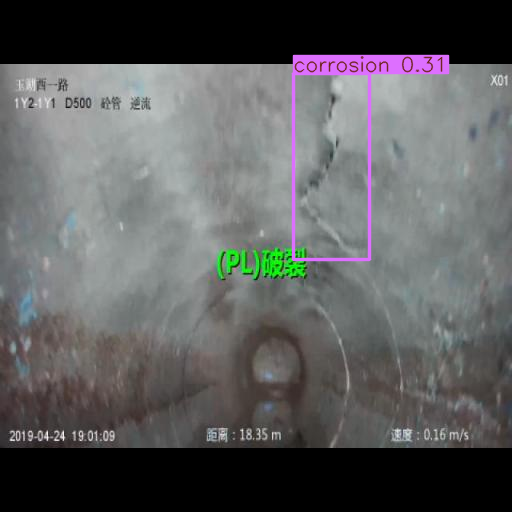

In [54]:
from ultralytics import YOLO
import glob
import random
from IPython.display import display

model = YOLO("/content/pipe_runs/pipe_defect_model/weights/best.pt")

images = glob.glob("/content/Combined_Pipe_Dataset/test/images/*")

print("Images found:", len(images))

image_path = random.choice(images)

results = model.predict(
    source=image_path,
    conf=0.25,
    imgsz=416,
    device=0,
    save=True
)

display(results[0].plot())

Images found: 128

image 1/1 /content/Combined_Pipe_Dataset/test/images/ds3_YS0400180_YS04001211_20210525204514_jpg.rf.69b91807d5b635cd59dd299343e3f373.jpg: 416x416 (no detections), 8.8ms
Speed: 1.1ms preprocess, 8.8ms inference, 0.5ms postprocess per image at shape (1, 3, 416, 416)
Results saved to /content/runs/detect/predict-2


array([[[  3,   5,  16],
        [ 27,  29,  40],
        [ 41,  39,  51],
        ...,
        [164, 171, 186],
        [140, 143, 158],
        [ 81,  84,  99]],

       [[  5,   7,  18],
        [ 31,  31,  43],
        [ 45,  43,  55],
        ...,
        [170, 179, 192],
        [153, 160, 175],
        [ 85,  91, 104]],

       [[  8,   8,  20],
        [ 34,  34,  46],
        [ 49,  47,  59],
        ...,
        [ 98, 113, 122],
        [107, 119, 131],
        [ 87,  99, 109]],

       ...,

       [[  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0],
        ...,
        [  0,   1,   0],
        [  0,   1,   0],
        [  0,   1,   0]],

       [[  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0],
        ...,
        [  0,   1,   0],
        [  0,   1,   0],
        [  0,   1,   0]],

       [[  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0],
        ...,
        [  0,   1,   0],
        [  0,   1,   0],
        [  0,   1,   0]]], shape=(512, 512, 3), dtype=uint8)
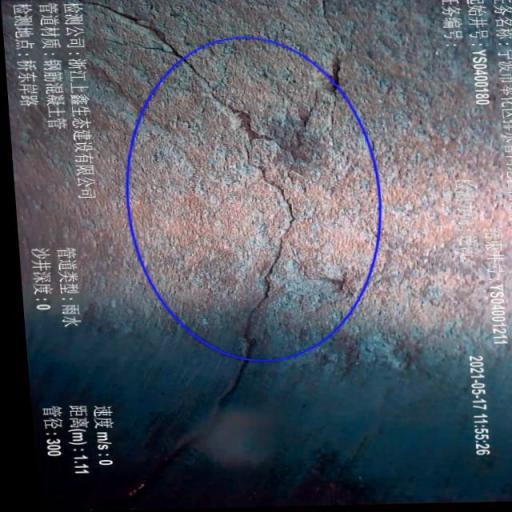

In [55]:
from ultralytics import YOLO
import glob
import random
from IPython.display import display

model = YOLO("/content/pipe_runs/pipe_defect_model/weights/best.pt")

images = glob.glob("/content/Combined_Pipe_Dataset/test/images/*")

print("Images found:", len(images))

image_path = random.choice(images)

results = model.predict(
    source=image_path,
    conf=0.25,
    imgsz=416,
    device=0,
    save=True
)

display(results[0].plot())

Images found: 128

image 1/1 /content/Combined_Pipe_Dataset/test/images/ds3_PL_1_s1ggx30xf5u_png_jpg.rf.c95845697c573a979d19b1e8bba24f86.jpg: 416x416 2 corrosions, 8.2ms
Speed: 1.2ms preprocess, 8.2ms inference, 1.2ms postprocess per image at shape (1, 3, 416, 416)
Results saved to /content/runs/detect/predict-3


array([[[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       ...,

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]]], shape=(512, 512, 3), dtype=uint8)
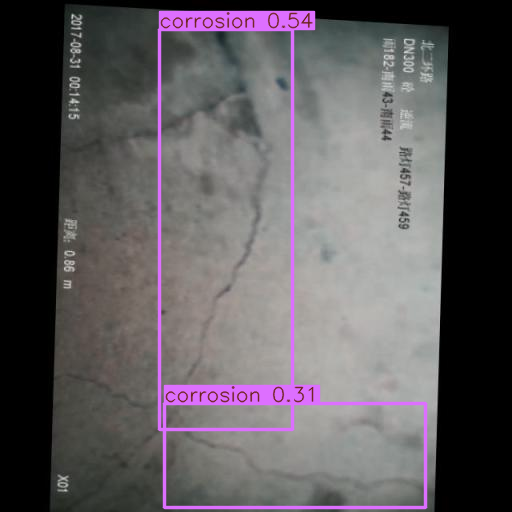

In [56]:
from ultralytics import YOLO
import glob
import random
from IPython.display import display

model = YOLO("/content/pipe_runs/pipe_defect_model/weights/best.pt")

images = glob.glob("/content/Combined_Pipe_Dataset/test/images/*")

print("Images found:", len(images))

image_path = random.choice(images)

results = model.predict(
    source=image_path,
    conf=0.25,
    imgsz=416,
    device=0,
    save=True
)

display(results[0].plot())

Images found: 128

image 1/1 /content/Combined_Pipe_Dataset/test/images/ds2_frame29_jpg.rf.f65aa08e8211db090fe200cbdbb6f565.jpg: 416x416 1 crack, 10.6ms
Speed: 1.4ms preprocess, 10.6ms inference, 1.6ms postprocess per image at shape (1, 3, 416, 416)
Results saved to /content/runs/detect/predict-4


array([[[190, 196, 201],
        [181, 187, 192],
        [164, 170, 175],
        ...,
        [179, 180, 190],
        [178, 177, 187],
        [180, 179, 189]],

       [[186, 192, 197],
        [173, 179, 184],
        [160, 166, 171],
        ...,
        [180, 181, 191],
        [180, 179, 189],
        [183, 182, 192]],

       [[167, 173, 178],
        [153, 159, 164],
        [147, 153, 158],
        ...,
        [176, 178, 186],
        [177, 179, 187],
        [181, 183, 191]],

       ...,

       [[116, 125, 134],
        [116, 125, 134],
        [114, 123, 132],
        ...,
        [128, 137, 146],
        [138, 147, 156],
        [138, 147, 156]],

       [[115, 124, 133],
        [111, 120, 129],
        [105, 114, 123],
        ...,
        [132, 141, 150],
        [138, 147, 156],
        [136, 145, 154]],

       [[122, 131, 140],
        [114, 123, 132],
        [102, 111, 120],
        ...,
        [136, 145, 154],
        [139, 148, 157],
        [136, 145, 154]]], shape=(416, 416, 3), dtype=uint8)
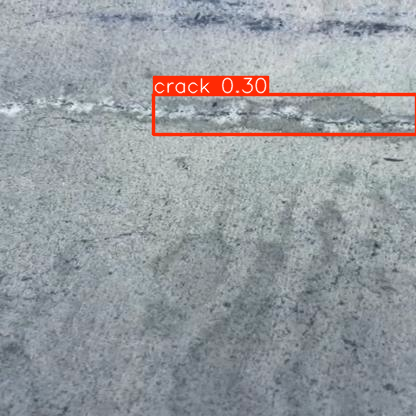

In [57]:
from ultralytics import YOLO
import glob
import random
from IPython.display import display

model = YOLO("/content/pipe_runs/pipe_defect_model/weights/best.pt")

images = glob.glob("/content/Combined_Pipe_Dataset/test/images/*")

print("Images found:", len(images))

image_path = random.choice(images)

results = model.predict(
    source=image_path,
    conf=0.25,
    imgsz=416,
    device=0,
    save=True
)

display(results[0].plot())


0: 416x416 1 crack, 2.5ms
1: 416x416 1 corrosion, 2.5ms
2: 416x416 1 corrosion, 2.5ms
3: 416x416 1 corrosion, 2.5ms
4: 416x416 1 void, 2.5ms
5: 416x416 1 crack, 2.5ms
6: 416x416 2 corrosions, 2.5ms
7: 416x416 2 corrosions, 2.5ms
8: 416x416 1 corrosion, 2.5ms
9: 416x416 1 crack, 2.5ms
Speed: 1.1ms preprocess, 2.5ms inference, 1.5ms postprocess per image at shape (1, 3, 416, 416)


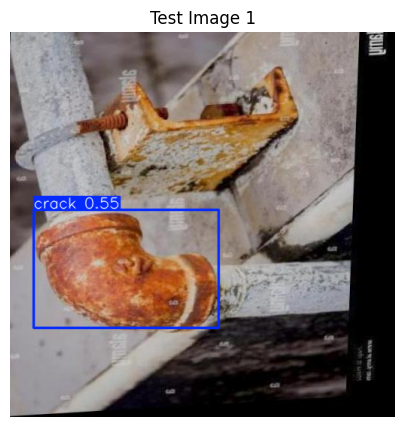

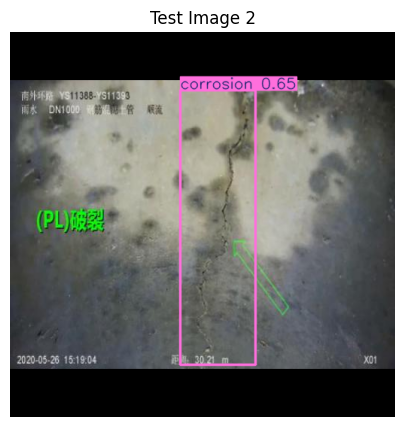

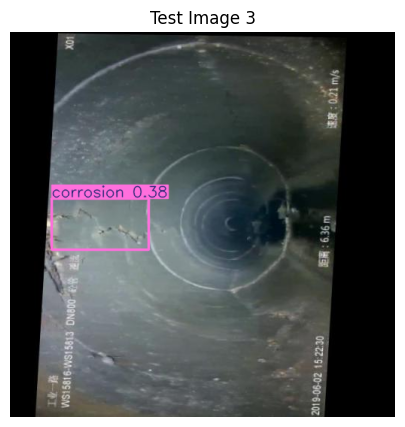

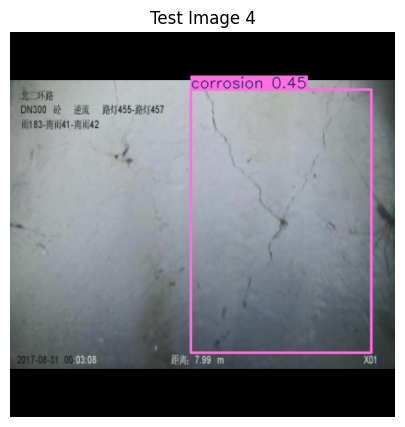

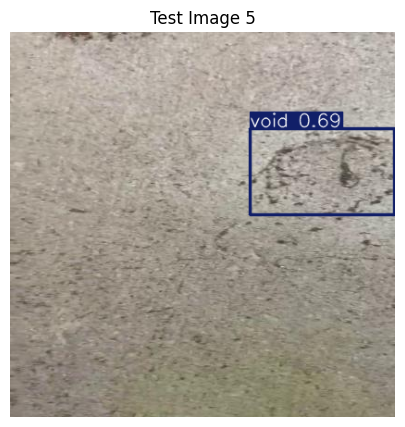

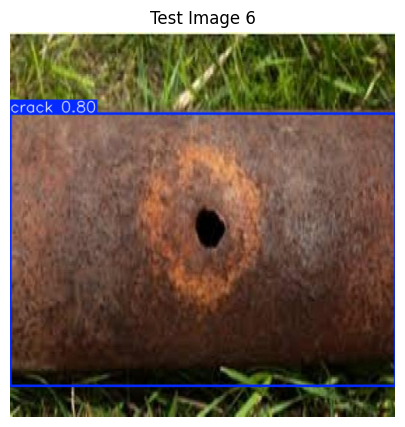

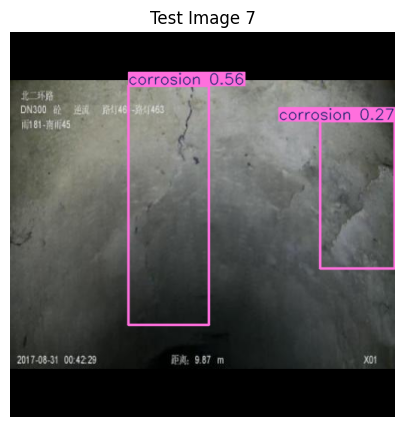

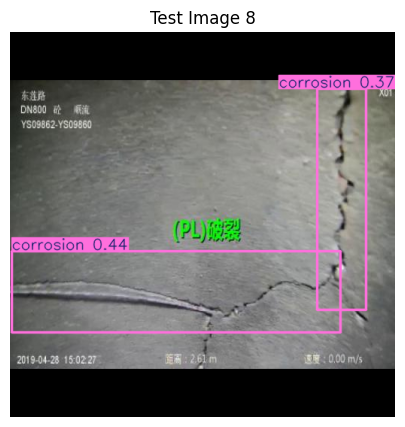

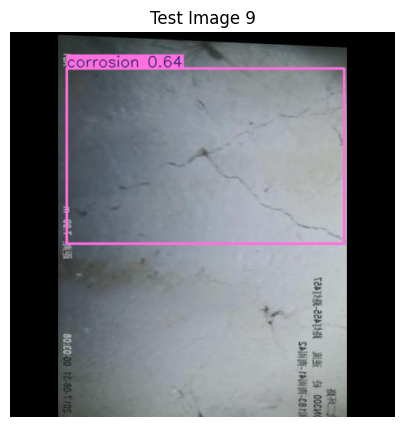

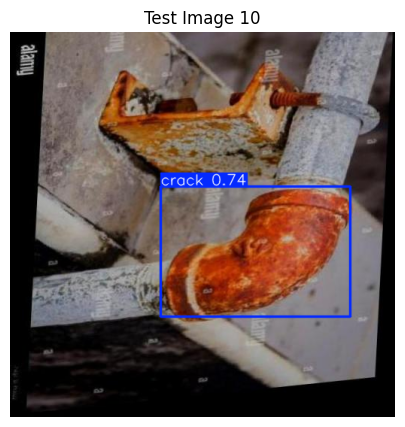

In [58]:
from ultralytics import YOLO
import glob
import matplotlib.pyplot as plt

model = YOLO("/content/pipe_runs/pipe_defect_model/weights/best.pt")

images = glob.glob("/content/Combined_Pipe_Dataset/test/images/*")[:10]

results = model.predict(
    source=images,
    conf=0.25,
    imgsz=416,
    device=0
)

for i, result in enumerate(results):
    plt.figure(figsize=(8, 5))
    plt.imshow(result.plot()[:, :, ::-1])
    plt.title(f"Test Image {i+1}")
    plt.axis("off")
    plt.show()

In [59]:
from pathlib import Path
import random

label_dir = Path("/content/Combined_Pipe_Dataset/train/labels")
image_dir = Path("/content/Combined_Pipe_Dataset/train/images")

files = list(label_dir.glob("*.txt"))
crack_files = []

for f in files:
    for line in f.read_text().splitlines():
        if line.strip() and int(line.split()[0]) == 0:
            crack_files.append(f)
            break

print("Images containing crack annotations:", len(crack_files))

if crack_files:
    selected = random.choice(crack_files)
    print("Selected annotation:", selected.name)
    print(selected.read_text())

Images containing crack annotations: 602
Selected annotation: ds2_frame28_jpg.rf.32f4f41cd938f1d049a4d0dc34d118c3.txt
0 0.7271634615384616 0.5997596153846154 0.0889423076923077 0.7956730769230769


Image: ds2_frame28_jpg.rf.32f4f41cd938f1d049a4d0dc34d118c3.jpg


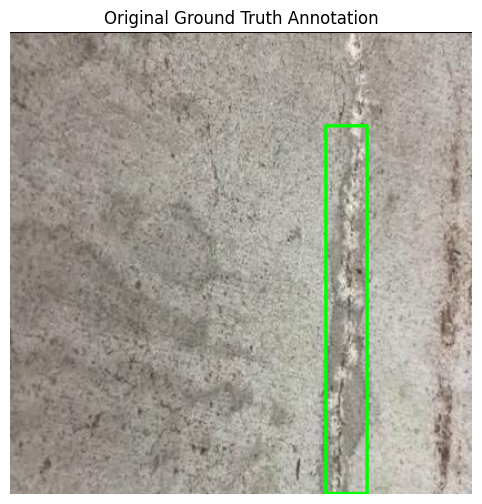

In [60]:
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

label_file = selected
image_file = Path("/content/Combined_Pipe_Dataset/train/images") / (selected.stem + ".jpg")

print("Image:", image_file.name)

img = cv2.imread(str(image_file))

if img is None:
    print("Image not found. Checking alternate extensions...")
    for ext in [".jpeg", ".png", ".webp"]:
        candidate = image_file.with_suffix(ext)
        if candidate.exists():
            img = cv2.imread(str(candidate))
            break

h, w = img.shape[:2]

for line in selected.read_text().splitlines():
    if not line.strip():
        continue

    cls, x, y, bw, bh = map(float, line.split())
    x1 = int((x - bw/2) * w)
    y1 = int((y - bh/2) * h)
    x2 = int((x + bw/2) * w)
    y2 = int((y + bh/2) * h)

    cv2.rectangle(img, (x1,y1), (x2,y2), (0,255,0), 2)

plt.figure(figsize=(10,6))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original Ground Truth Annotation")
plt.axis("off")
plt.show()

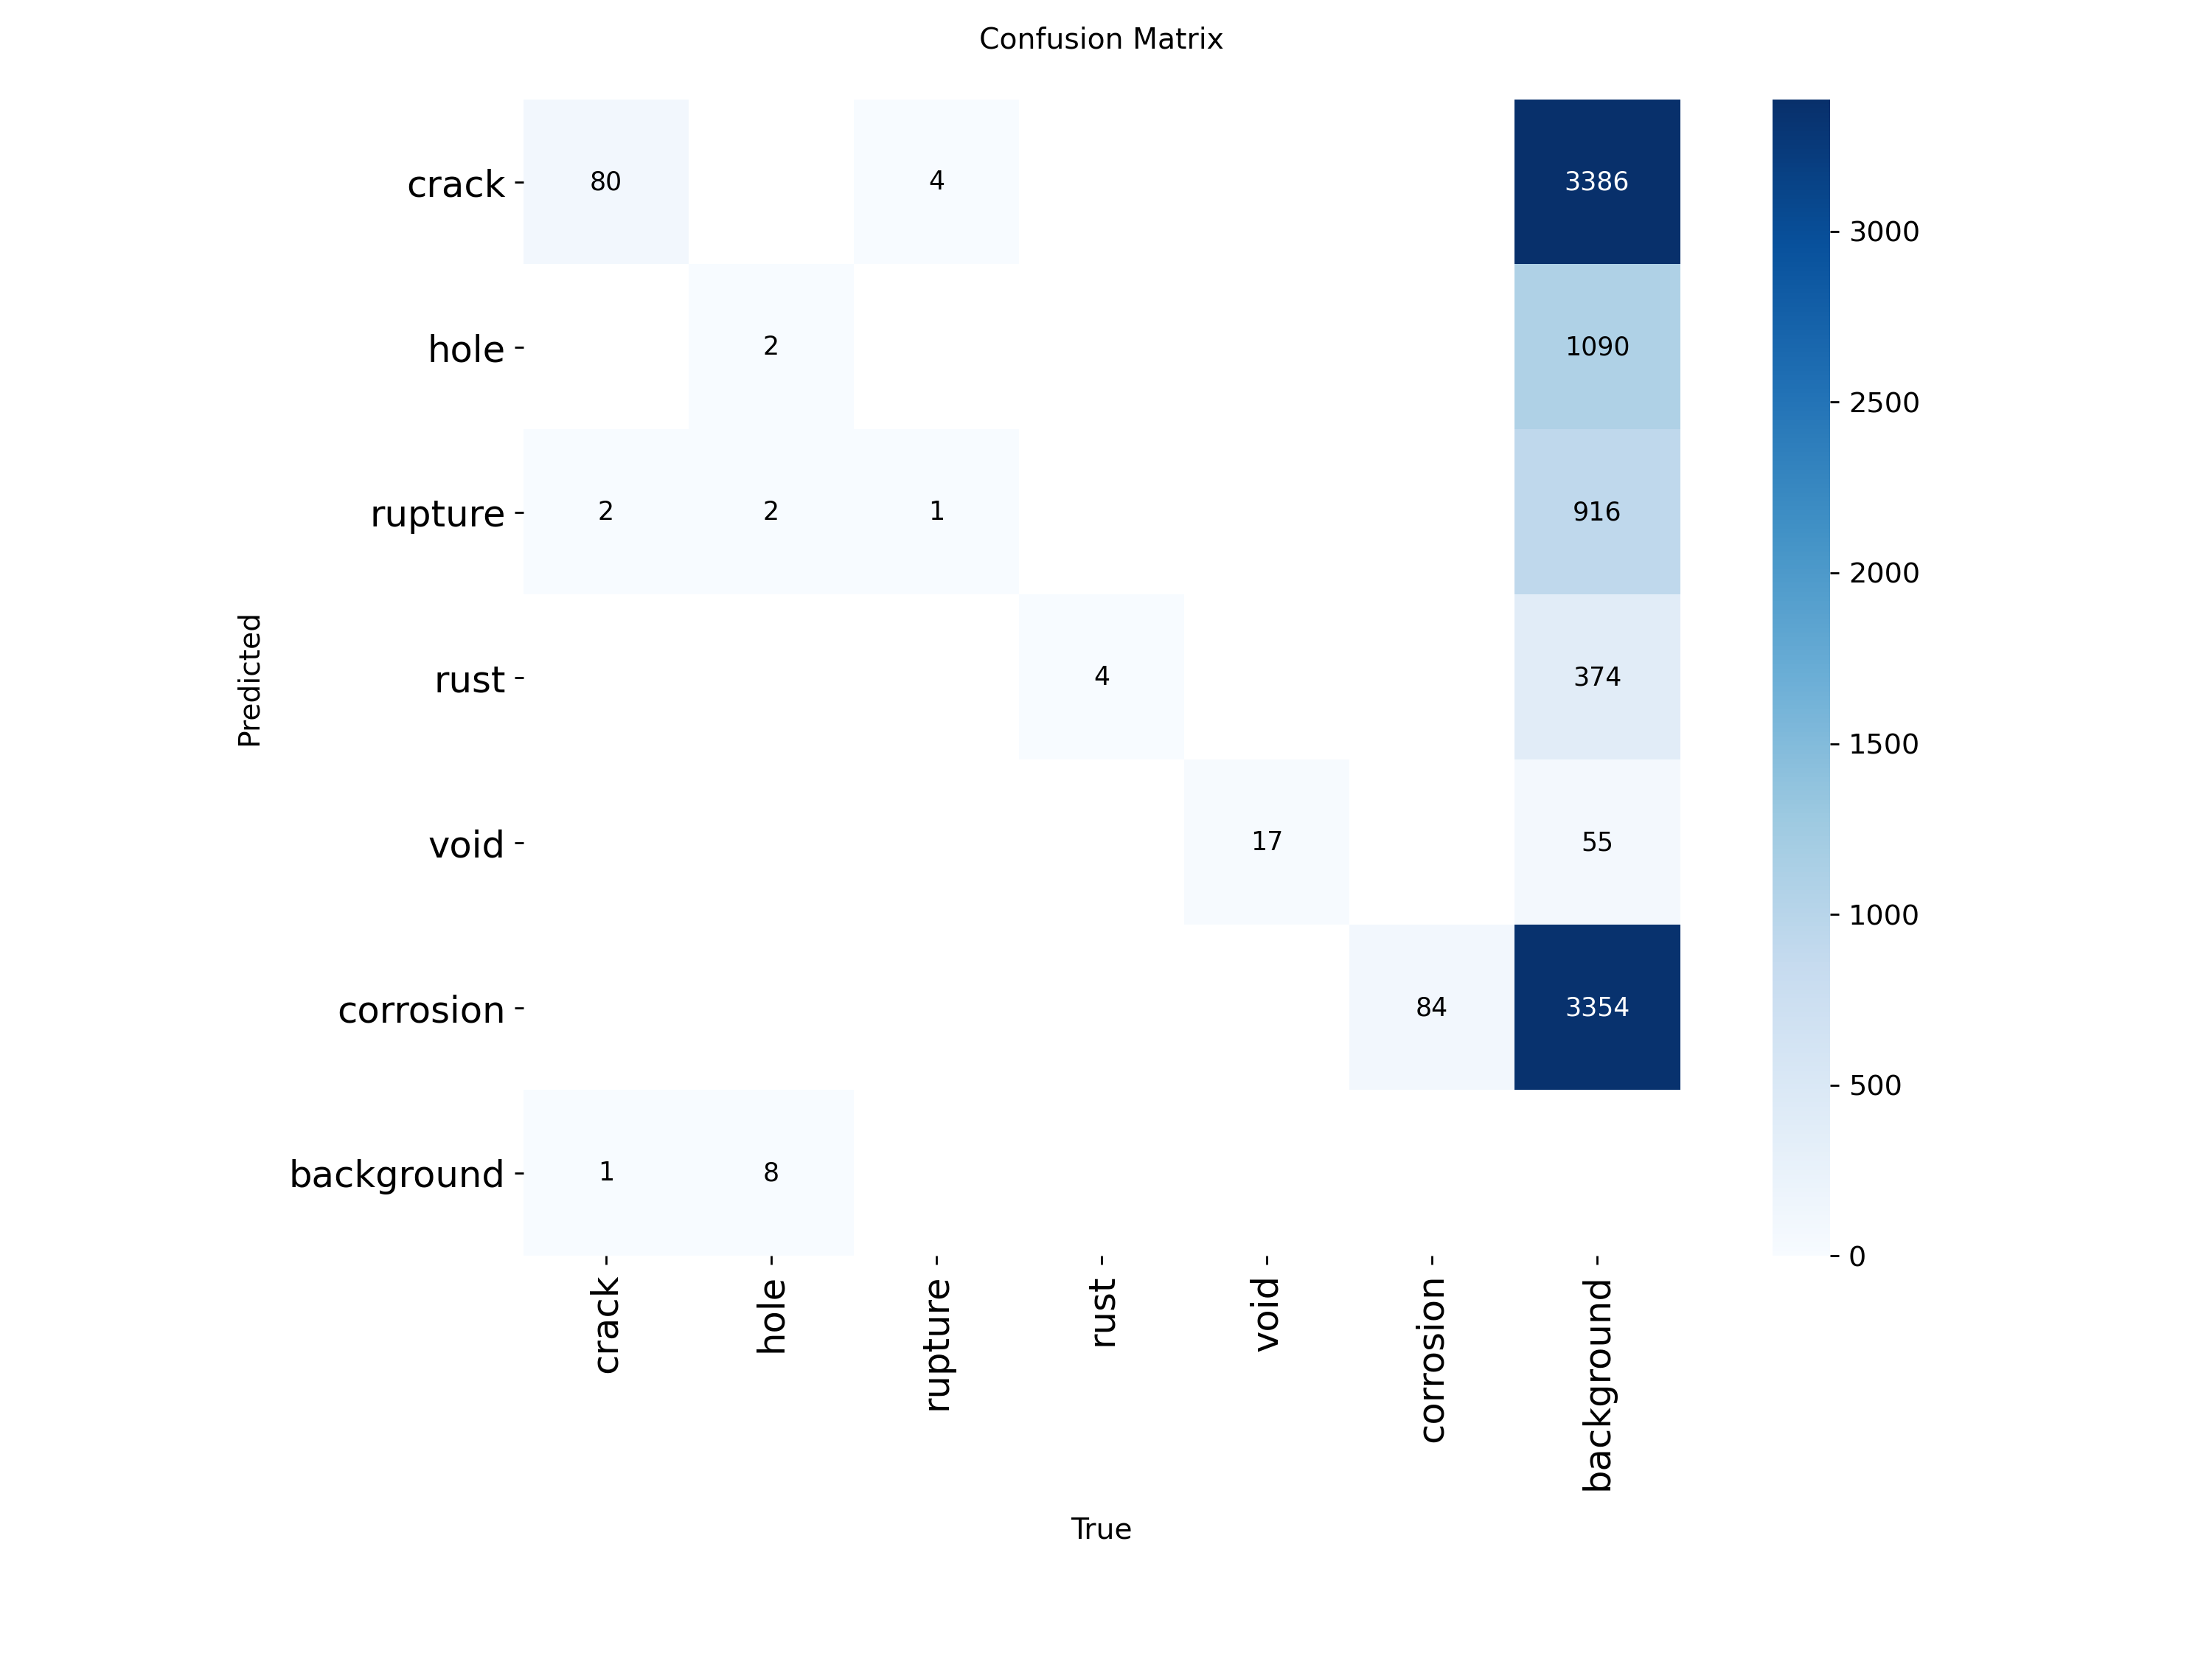

In [61]:
from IPython.display import display, Image

display(Image(filename="/content/pipe_runs/pipe_defect_model/confusion_matrix.png"))

ACTUAL ANNOTATION:


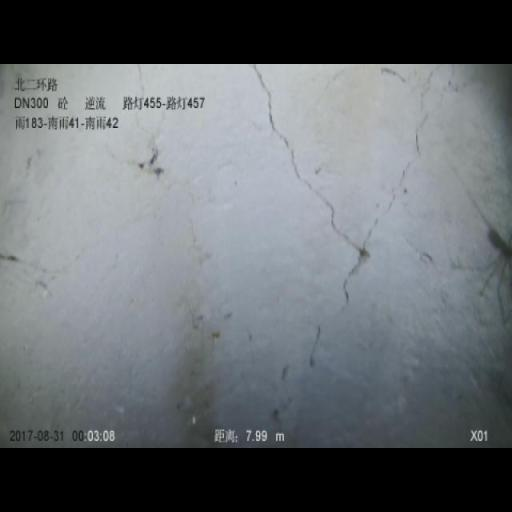

MODEL PREDICTION:

image 1/1 /content/Combined_Pipe_Dataset/test/images/ds3_PL_1_ruknpbiqcic_png_jpg.rf.b90d22481f24198573c409f9f006b1a8.jpg: 416x416 1 corrosion, 8.4ms
Speed: 1.6ms preprocess, 8.4ms inference, 1.4ms postprocess per image at shape (1, 3, 416, 416)


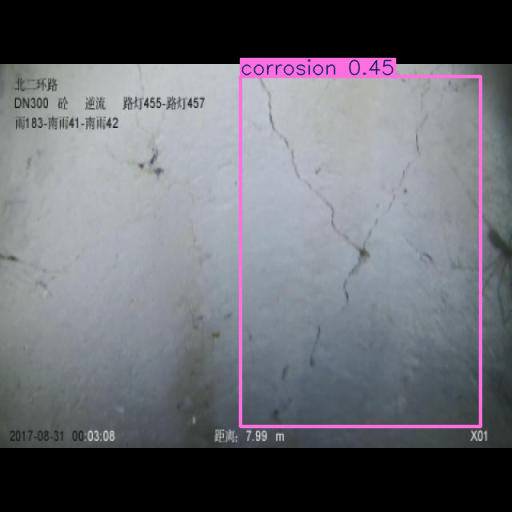

In [62]:
import random
from pathlib import Path
from PIL import Image
from IPython.display import display
from ultralytics import YOLO

base = Path("/content/Combined_Pipe_Dataset/test")

label_files = list((base / "labels").glob("*.txt"))
selected_label = random.choice(label_files)

image_path = base / "images" / (selected_label.stem + ".jpg")

if not image_path.exists():
    image_path = next(
        p for p in (base / "images").glob("*")
        if p.stem == selected_label.stem
    )

model = YOLO("/content/pipe_runs/pipe_defect_model/weights/best.pt")

print("ACTUAL ANNOTATION:")
display(Image.open(image_path))

print("MODEL PREDICTION:")
result = model.predict(str(image_path), conf=0.25, device=0)[0]
display(Image.fromarray(result.plot()[..., ::-1]))

In [63]:
from pathlib import Path

label_path = Path("/content/Combined_Pipe_Dataset/test/labels") / (Path(image_path).stem + ".txt")

names = model.names

print("GROUND TRUTH LABELS:")

if label_path.exists():
    for line in label_path.read_text().splitlines():
        if line.strip():
            cls, x, y, w, h = map(float, line.split())
            print("Actual class:", names[int(cls)])
else:
    print("No annotation found!")

GROUND TRUTH LABELS:
Actual class: corrosion
Actual class: corrosion
Actual class: corrosion


In [64]:
from ultralytics import YOLO

model = YOLO("/content/pipe_runs/pipe_defect_model/weights/best.pt")

metrics = model.val(
    data="/content/Combined_Pipe_Dataset/data.yaml",
    split="test",
    imgsz=416,
    device=0,
    plots=True,
    project="/content/pipe_runs",
    name="final_evaluation"
)

print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)
print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,598,266 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1264.1±469.0 MB/s, size: 27.3 KB)
val: Scanning /content/Combined_Pipe_Dataset/test/labels.cache... 128 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 128/128 33.6Mit/s 0.0s
WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 7, len(boxes) = 189. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 4.0it/s 2.0s
                   all        128        189      0.603      0.466       0.53      0.301
                 crack         61         76        0.8      0.618      0.751       0.44
                  hole         

In [65]:
from google.colab import files

uploaded = files.upload()

Saving pipeeeee.jpg to pipeeeee.jpg



image 1/1 /content/pipeeeee.jpg: 288x416 1 crack, 1 hole, 10.2ms
Speed: 1.4ms preprocess, 10.2ms inference, 1.6ms postprocess per image at shape (1, 3, 288, 416)


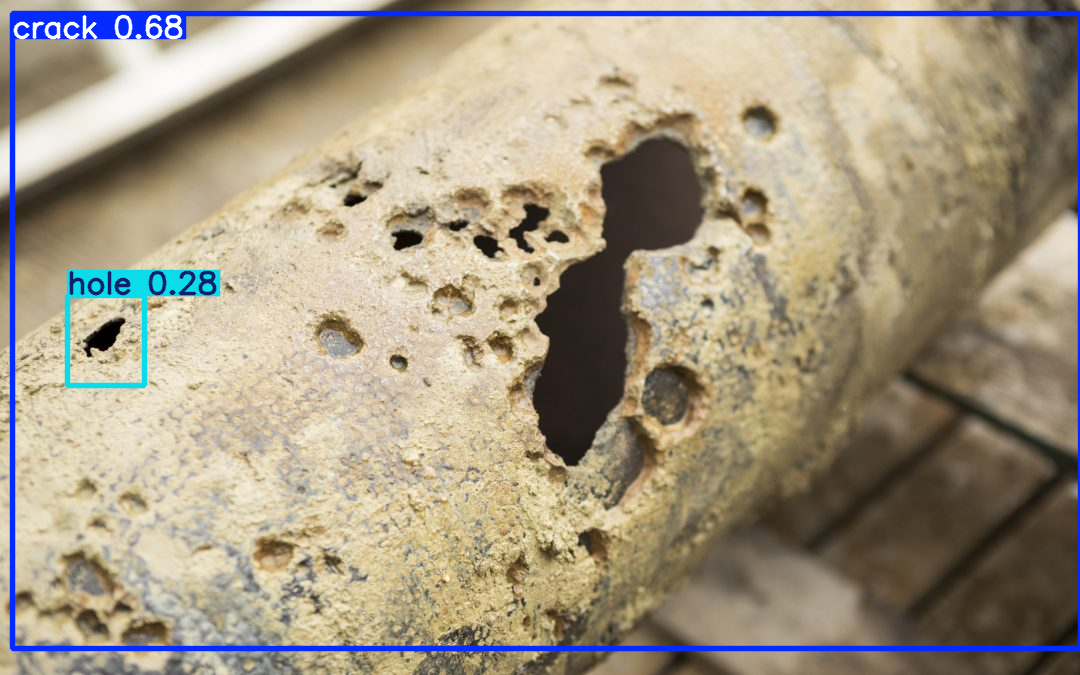

In [66]:
from ultralytics import YOLO
from IPython.display import display
from PIL import Image

model = YOLO("/content/pipe_runs/pipe_defect_model/weights/best.pt")

image_path = list(uploaded.keys())[0]

results = model.predict(
    source=image_path,
    conf=0.25,
    imgsz=416,
    device=0
)

display(Image.fromarray(results[0].plot()[:, :, ::-1]))

In [67]:
results = model.predict(
    source=image_path,
    conf=0.10,
    imgsz=640,
    device=0
)

display(results[0].plot()[:, :, ::-1])


image 1/1 /content/pipeeeee.jpg: 416x640 1 crack, 1 hole, 26.8ms
Speed: 2.1ms preprocess, 26.8ms inference, 1.5ms postprocess per image at shape (1, 3, 416, 640)


array([[[182, 173, 144],
        [182, 173, 144],
        [183, 173, 146],
        ...,
        [  4,  42, 255],
        [  4,  42, 255],
        [  4,  42, 255]],

       [[183, 174, 145],
        [183, 174, 145],
        [185, 175, 148],
        ...,
        [  4,  42, 255],
        [  4,  42, 255],
        [  4,  42, 255]],

       [[185, 175, 148],
        [186, 176, 149],
        [187, 177, 150],
        ...,
        [  4,  42, 255],
        [  4,  42, 255],
        [  4,  42, 255]],

       ...,

       [[211, 197, 160],
        [210, 198, 160],
        [211, 197, 160],
        ...,
        [ 36,  46, 115],
        [  4,  42, 255],
        [  4,  42, 255]],

       [[210, 196, 159],
        [211, 197, 160],
        [211, 197, 160],
        ...,
        [  4,  42, 255],
        [  4,  42, 255],
        [  4,  42, 255]],

       [[210, 196, 159],
        [210, 196, 159],
        [210, 196, 159],
        ...,
        [  4,  42, 255],
        [  4,  42, 255],
        [  4,  42, 255]]

In [68]:
import shutil
import os
from google.colab import files

# Create final project folder
final_dir = "/content/FINAL_PIPE_PROJECT"
os.makedirs(final_dir, exist_ok=True)

# Save trained weights
shutil.copy(
    "/content/pipe_runs/pipe_defect_model/weights/best.pt",
    final_dir + "/best.pt"
)

# Save training results
shutil.copytree(
    "/content/pipe_runs/pipe_defect_model",
    final_dir + "/training",
    dirs_exist_ok=True
)

# Save predictions if available
if os.path.exists("/content/pipe_runs/predictions"):
    shutil.copytree(
        "/content/pipe_runs/predictions",
        final_dir + "/predictions",
        dirs_exist_ok=True
    )

# Create ZIP
shutil.make_archive(
    "/content/FINAL_PIPE_PROJECT",
    "zip",
    final_dir
)

files.download("/content/FINAL_PIPE_PROJECT.zip")

print("FINAL PROJECT BACKUP READY!")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

FINAL PROJECT BACKUP READY!
